In [4]:

from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive (1).zip


In [5]:

import pandas as pd
import zipfile
import io

# Get the uploaded ZIP file's actual name
zip_name = next(name for name in uploaded if name.endswith(".zip"))

with zipfile.ZipFile(io.BytesIO(uploaded[zip_name]), "r") as z:
    print("Files inside ZIP:", z.namelist())

    # Find the CSV file
    csv_name = next(name for name in z.namelist()
                    if name.lower().endswith(".csv"))

    with z.open(csv_name) as f:
        df = pd.read_csv(f, encoding="latin-1")

# Keep only the useful columns
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nLabel counts:")
print(df["label"].value_counts())


Files inside ZIP: ['spam.csv']

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape: (5572, 2)

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64


In [6]:

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Remove duplicate messages
print("\nDuplicates before cleaning:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

# Convert labels into numbers
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("\nDataset after cleaning:")
print("Total messages:", len(df))
print(df.head())
print("\nLabel distribution:")
print(df["label"].value_counts())


Missing values:
label      0
message    0
dtype: int64

Duplicates before cleaning: 403

Dataset after cleaning:
Total messages: 5169
  label                                            message  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0

Label distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [7]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# Separate input messages and output labels
X = df["message"]
y = df["label_num"]

# Split the dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create the model
model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", MultinomialNB())
])

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Model trained successfully!
Training messages: 4135
Testing messages: 1034


Model Evaluation Results
------------------------
Accuracy:  96.62%
Precision: 98.98%
Recall:    74.05%
F1-Score:  84.72%

Classification Report:
                precision    recall  f1-score   support

Ham (Not Spam)       0.96      1.00      0.98       903
          Spam       0.99      0.74      0.85       131

      accuracy                           0.97      1034
     macro avg       0.98      0.87      0.91      1034
  weighted avg       0.97      0.97      0.96      1034



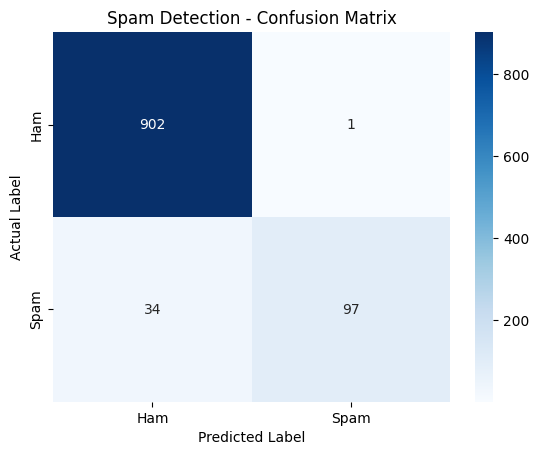

In [8]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# Predict labels for the testing messages
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Ham (Not Spam)", "Spam"]
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Spam Detection - Confusion Matrix")
plt.show()


In [9]:

def check_message(message):
    prediction = model.predict([message])[0]
    probabilities = model.predict_proba([message])[0]

    if prediction == 1:
        print("Result: SPAM")
    else:
        print("Result: HAM (NOT SPAM)")

    print(f"Spam probability: {probabilities[1] * 100:.2f}%")

# Try sample messages
check_message("Congratulations! You have won a free prize. Call now!")
print()
check_message("Hey, are we meeting for lunch today?")


Result: SPAM
Spam probability: 84.27%

Result: HAM (NOT SPAM)
Spam probability: 0.26%


In [11]:

# Interactive Spam Message Detector

message = input("Enter a message to check: ")

prediction = model.predict([message])[0]
spam_probability = model.predict_proba([message])[0][1]

print("\n--- Spam Detection Result ---")

if prediction == 1:
    print("🚨 This message is SPAM!")
else:
    print("✅ This message is HAM (NOT SPAM).")

print(f"Spam probability: {spam_probability * 100:.2f}%")

Enter a message to check: Hey, are we meeting for lunch today?

--- Spam Detection Result ---
✅ This message is HAM (NOT SPAM).
Spam probability: 0.26%
